In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

In [2]:
df = pd.read_csv("boxes.csv")
df.shape

/tmp/ipykernel_13960/3725808996.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("boxes.csv")


(1000000, 10)

In [3]:
df.head()

,seq_name,frame_h,frame_w,altitude,x_left,y_top,width,height,pos_x,pos_y
0,PG1_H250_MR_stitch150cm_NY_170726_06_HR_149512...,960,1280,250,965,289,100,100,1015,339
1,pg1_dev_H675_walking_Q_NY_1509279918.avi.seq,960,1280,675,591,202,39,93,617,276
2,PG1_DL_H290_Office_Desk_1494404949.avi.seq,960,1280,290,443,311,141,145,517,386
3,PG1_H255_MR_PG_5min_4min_empty2_1499849540.avi...,960,1280,255,515,578,100,100,565,628
4,PG1_DL_H300_Stitch_HD_NY_St170925_LT_149978785...,960,1280,300,656,718,154,239,735,857


In [4]:
df = df[df["altitude"] != "NODATA"]
df["altitude"] = pd.to_numeric(df["altitude"])

df = df[(df["width"] > 0) & (df["height"] > 0)]


In [5]:
df.shape

(999980, 10)

In [6]:
df["seq_name"].unique().shape

(5965,)

In [7]:
df["seq_name"].unique()[:10]

array(['PG1_H250_MR_stitch150cm_NY_170726_06_HR_1495121650.avi.seq',
       'pg1_dev_H675_walking_Q_NY_1509279918.avi.seq',
       'PG1_DL_H290_Office_Desk_1494404949.avi.seq',
       'PG1_H255_MR_PG_5min_4min_empty2_1499849540.avi.seq',
       'PG1_DL_H300_Stitch_HD_NY_St170925_LT_1499787853_f_00000_01800.avi.seq',
       'QA_PG1_H350_office_HD_edg_NV_NoPIR_07_12_19_09_2017.avi.seq',
       'PG1_H350_office_MR_NY_15stnd_U20_1499850906.avi.seq',
       'QA_Home_Amit_H300_21_13_03_42_2015.avi.seq',
       'PG1_H300_office_MR_NY_NoPIR_09_12_09_31_2017.avi.seq',
       'QA_PG1_H300_office_MR_NV_hardcase_NoPIR_09_12_16_26_2017.avi.seq'],
      dtype=object)

In [22]:
df.groupby(by=["frame_h", "frame_w"])["seq_name"].count()

frame_h  frame_w
480      640         21756
720      1280        60408
960      1280       917816
Name: seq_name, dtype: int64

In [23]:
640 / 480, 1280 / 720, 1280 / 960

(1.3333333333333333, 1.7777777777777777, 1.3333333333333333)

In [9]:
df["pos_x_rel"] = df["pos_x"] / df["frame_w"]
df["pos_y_rel"] = df["pos_y"] / df["frame_h"]

df["x_left_rel"] = df["x_left"] / df["frame_w"]
df["y_top_rel"] = df["y_top"] / df["frame_h"]

df["width_rel"] = df["width"] / df["frame_w"]
df["height_rel"] = df["height"] / df["frame_h"]

df["frame_ratio"] = df["frame_h"] / df["frame_w"]
df["box_ratio"] = df["height"] / df["width"]
df["box_center_x_rel"] = df["x_left_rel"] + df["width_rel"] / 2
df["box_center_y_rel"] = df["y_top_rel"] + df["height_rel"] / 2

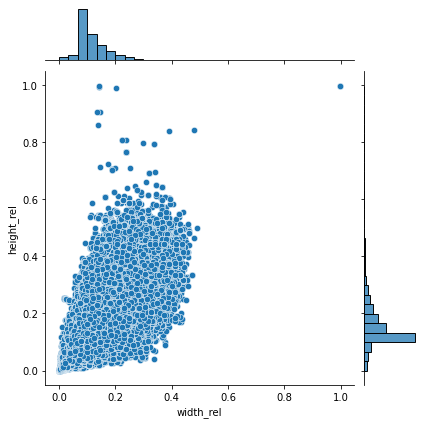

In [156]:
sns.jointplot(data=df, x="width_rel", y="height_rel", marginal_kws=dict(bins=30), s=40)

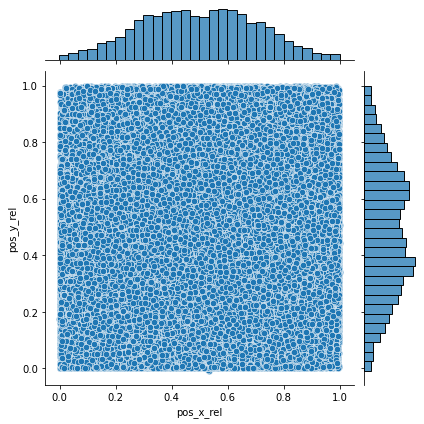

In [157]:
sns.jointplot(data=df, x="pos_x_rel", y="pos_y_rel", marginal_kws=dict(bins=30), s=40)

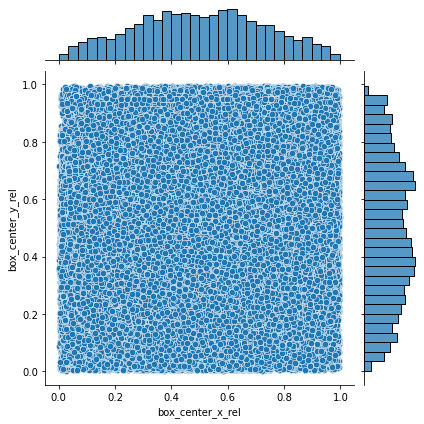

In [158]:
sns.jointplot(data=df, x="box_center_x_rel", y="box_center_y_rel", marginal_kws=dict(bins=30), s=40)

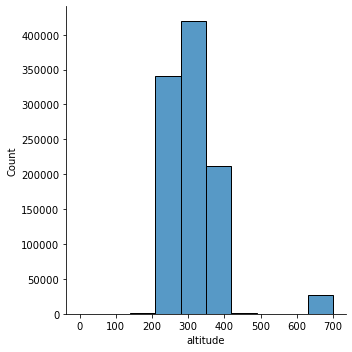

In [159]:
sns.displot(data=df, x="altitude", bins=10)

<AxesSubplot:>

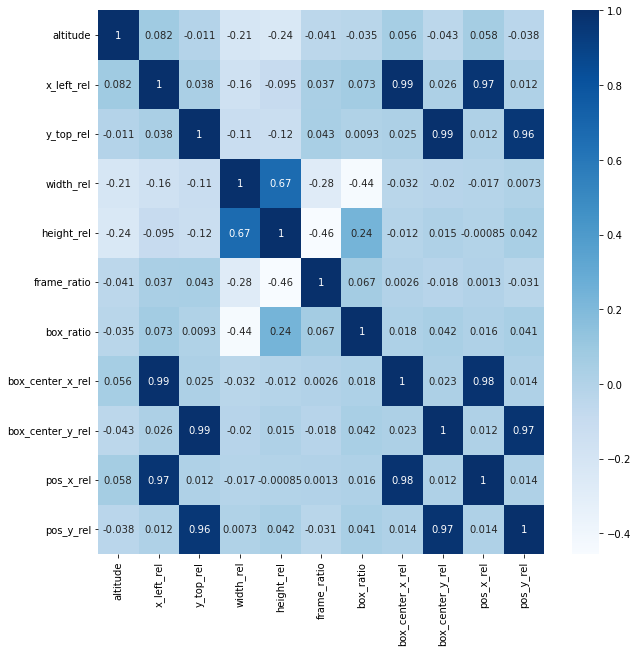

In [160]:
corr = df[[
    "altitude",
    "x_left_rel",
    "y_top_rel",
    "width_rel",
    "height_rel",
    "frame_ratio",
    "box_ratio",
    "box_center_x_rel",
    "box_center_y_rel",
    "pos_x_rel",
    "pos_y_rel"
]].corr()
plt.figure(figsize=(10, 10))
sns.heatmap(corr, cmap="Blues", annot=True)

In [161]:
np.rad2deg(np.arctan2(-1, 0))

-90.0

(0.0, 1.0)

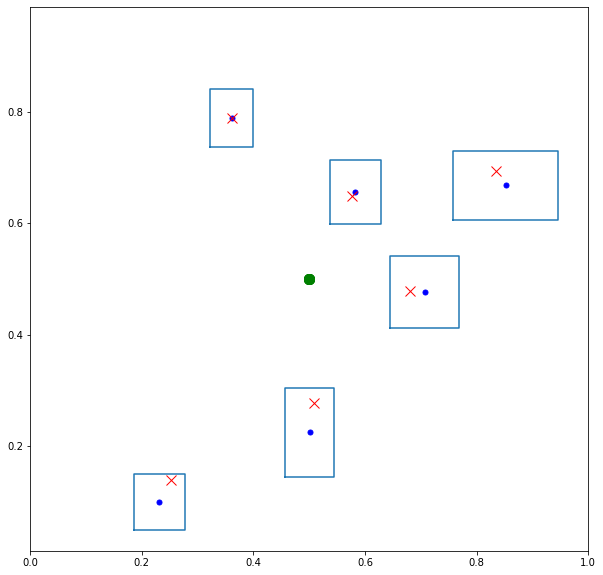

In [162]:
idx = 125
plt.figure(figsize=(10, 10))
plt.axis("equal")
for idx in np.arange(5504, 5510):
    x, y, w, h, pos_x, pos_y, center_x, center_y = df.iloc[idx][[
        "x_left_rel", "y_top_rel", "width_rel", "height_rel", "pos_x_rel", "pos_y_rel", "box_center_x_rel", "box_center_y_rel"]].values

    

    plt.plot(0.5, 0.5, 'go', markersize=10)
    plt.plot(*np.array([
        [x, y],
        [x, y + h],
        [x + w, y + h],
        [x + w, y],
        [x, y]
    ]).T, c="tab:blue")
    plt.plot(center_x, center_y, 'bo', markersize=5)

    plt.plot(pos_x, pos_y, 'rx', markersize=10)

plt.xlim(0, 1)
plt.ylim(0, 1)

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    df[["box_center_x_rel", "box_center_y_rel", "box_ratio", "frame_ratio"]].values, df[["pos_x_rel", "pos_y_rel"]].values, test_size=0.1, random_state=42)

In [35]:
pipe = Pipeline([
    ("preprocess", StandardScaler()),
    ("model", Ridge())
])

params = {
    "model__alpha": [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 1.5, 2, 5, 10, 20, 50],
}

model_x = GridSearchCV(pipe, params)
model_x.fit(X_train, y_train[:, 0])

model_y = GridSearchCV(pipe, params)
model_y.fit(X_train, y_train[:, 1])

GridSearchCV(estimator=Pipeline(steps=[('preprocess', StandardScaler()),
                                       ('model', Ridge())]),
             param_grid={'model__alpha': [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1,
                                          1.5, 2, 5, 10, 20, 50]})

In [36]:
model_x.score(X_test, y_test[:, 0]), model_y.score(X_test, y_test[:, 1])

(0.9572736852694044, 0.9440551323933202)

In [51]:
pred_x = model_x.predict(X_test)
pred_y = model_y.predict(X_test)

mean_squared_error(y_test[:, 0], pred_x), mean_squared_error(y_test[:, 1], pred_y)

(0.0018533943708276374, 0.0027274466066579146)

In [59]:
mean_absolute_error(y_test[:, 0], pred_x), mean_absolute_error(y_test[:, 1], pred_y)

(0.023306714793357216, 0.028260449122280602)

In [60]:
mean_squared_error(X_test[:, 0], y_test[:, 0]), mean_squared_error(X_test[:, 1], y_test[:, 1])

(0.0025297243631029844, 0.003499864100532397)

In [61]:
mean_absolute_error(X_test[:, 0], y_test[:, 0]), mean_absolute_error(X_test[:, 1], y_test[:, 1])

(0.02561301616657333, 0.02980824894275664)

(0.0, 1.0)

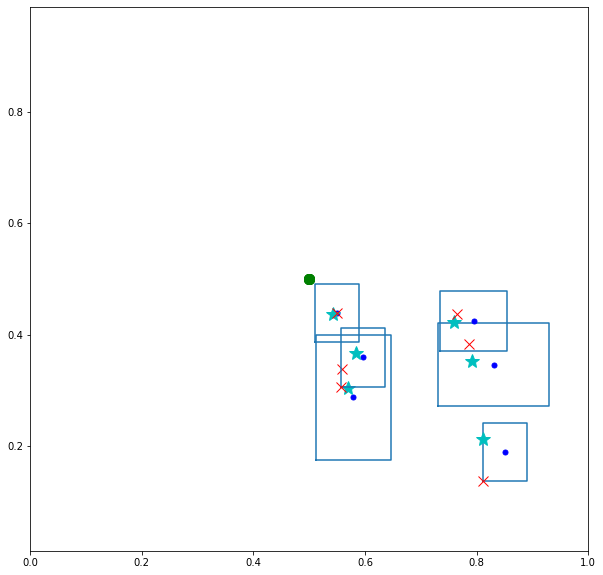

In [43]:
idx = 125
plt.figure(figsize=(10, 10))
plt.axis("equal")
for idx in np.arange(2504, 2510):
    x, y, w, h, pos_x, pos_y, center_x, center_y, box_ratio, frame_ratio = df.iloc[idx][[
        "x_left_rel", "y_top_rel",
        "width_rel", "height_rel",
        "pos_x_rel", "pos_y_rel",
        "box_center_x_rel", "box_center_y_rel",
        "box_ratio", "frame_ratio"
    ]].values

    pred_x = model_x.predict([[center_x, center_y, box_ratio, frame_ratio]])
    pred_y = model_y.predict([[center_x, center_y, box_ratio, frame_ratio]])

    plt.plot(0.5, 0.5, 'go', markersize=10)
    plt.plot(*np.array([
        [x, y],
        [x, y + h],
        [x + w, y + h],
        [x + w, y],
        [x, y]
    ]).T, c="tab:blue")
    plt.plot(center_x, center_y, 'bo', markersize=5)
    
    plt.plot(pred_x, pred_y, 'c*', markersize=15)
    plt.plot(pos_x, pos_y, 'rx', markersize=10)
    
    

plt.xlim(0, 1)
plt.ylim(0, 1)

In [75]:
df["x_dist"] = df["box_center_x_rel"].apply(lambda x: np.abs(x - 0.5))
df["y_dist"] = df["box_center_y_rel"].apply(lambda x: np.abs(x - 0.5))
df["dist"] = np.linalg.norm(df[["x_dist", "y_dist"]].values, axis=1)

df["pos_x_dist"] = df["pos_x_rel"].apply(lambda x: np.abs(x - 0.5))
df["pos_y_dist"] = df["pos_y_rel"].apply(lambda x: np.abs(x - 0.5))
df["pos_dist"] = np.linalg.norm(df[["pos_x_dist", "pos_y_dist"]].values, axis=1)

df["angle"] = np.arctan2(df["y_dist"].values, df["x_dist"].values)
df["pos_angle"] = np.arctan2(df["pos_y_dist"].values, df["pos_x_dist"].values)

In [77]:
X_train, X_test, y_train, y_test = train_test_split(
    df[["dist", "angle", "box_ratio", "frame_ratio"]].values,
    df[["pos_dist", "pos_angle"]].values,
    test_size=0.1, random_state=42
)

pipe = Pipeline([
    ("preprocess", StandardScaler()),
    ("model", Ridge())
])

params = {
    "model__alpha": [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 1.5, 2, 5, 10, 20, 50],
}

model_x = GridSearchCV(pipe, params)
model_x.fit(X_train, y_train[:, 0])

model_y = GridSearchCV(pipe, params)
model_y.fit(X_train, y_train[:, 1])

pred_x = model_x.predict(X_test)
pred_y = model_y.predict(X_test)

print(mean_squared_error(y_test[:, 0], pred_x), mean_squared_error(y_test[:, 1], pred_y))
print(mean_absolute_error(y_test[:, 0], pred_x), mean_absolute_error(y_test[:, 1], pred_y))

0.002297163333018171 0.015272133775228245
0.03162594060318113 0.06392866520139678
